In [1]:
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import InMemorySaver
from langchain_openai import ChatOpenAI
from typing import TypedDict
from dotenv import load_dotenv
load_dotenv()

True

In [2]:
llm = ChatOpenAI(model="gpt-4o-mini")

In [3]:
class JokeState(TypedDict):

    topic: str
    joke: str
    explaination: str

In [4]:
def generate_joke(state: JokeState):

    prompt = f"""Generate a joke about {state['topic']} and explain it in detail."""
    response = llm.invoke(prompt)

    return {'joke': response}

In [5]:
def generate_explaination(state: JokeState):

    prompt = f"Explain the joke: {state['joke']}"
    response = llm.invoke(prompt)

    return {'explaination': response}

In [6]:
graph = StateGraph(JokeState)

graph.add_node('generate_joke', generate_joke)
graph.add_node('generate_explaination', generate_explaination)

graph.add_edge(START, 'generate_joke')
graph.add_edge('generate_joke', 'generate_explaination')
graph.add_edge('generate_explaination', END)

checkpointer = InMemorySaver()


workflow = graph.compile(checkpointer=checkpointer)

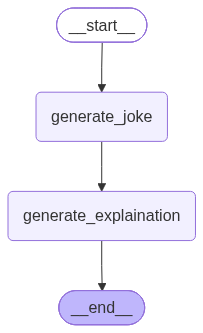

In [7]:
workflow

In [8]:
config_1 = {'configurable': {'thread_id': '1'}}
final_joke = workflow.invoke({'topic': 'pizza'}, config=config_1)
print(final_joke)

{'topic': 'pizza', 'joke': AIMessage(content='**Joke:** Why did the pizza maker go broke? Because he just couldn’t make enough dough!\n\n**Explanation:** \n\n1. **Wordplay**: The humor in this joke primarily arises from a play on words involving the term "dough." In culinary terms, "dough" refers to the mixture of flour and liquid that is used to make pizza crust. So, it\'s a very literal reference to the pizza making process.\n\n2. **Double Meaning**: The joke also utilizes the colloquial meaning of "dough," which is slang for money. When someone says they "can’t make enough dough," it typically refers to not earning enough money to sustain themselves financially.\n\n3. **Context**: The context of a "pizza maker" being broke sets up the expectation that we are discussing a serious financial situation. The punchline twists this expectation by linking the literal and figurative meanings of "dough." \n\n4. **Humor Structure**: The joke follows a classic structure of setup and punchline:\

In [9]:
workflow.get_state(config_1)

StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Joke:** Why did the pizza maker go broke? Because he just couldn’t make enough dough!\n\n**Explanation:** \n\n1. **Wordplay**: The humor in this joke primarily arises from a play on words involving the term "dough." In culinary terms, "dough" refers to the mixture of flour and liquid that is used to make pizza crust. So, it\'s a very literal reference to the pizza making process.\n\n2. **Double Meaning**: The joke also utilizes the colloquial meaning of "dough," which is slang for money. When someone says they "can’t make enough dough," it typically refers to not earning enough money to sustain themselves financially.\n\n3. **Context**: The context of a "pizza maker" being broke sets up the expectation that we are discussing a serious financial situation. The punchline twists this expectation by linking the literal and figurative meanings of "dough." \n\n4. **Humor Structure**: The joke follows a classic structure of 

In [10]:
list(workflow.get_state_history(config_1))

[StateSnapshot(values={'topic': 'pizza', 'joke': AIMessage(content='**Joke:** Why did the pizza maker go broke? Because he just couldn’t make enough dough!\n\n**Explanation:** \n\n1. **Wordplay**: The humor in this joke primarily arises from a play on words involving the term "dough." In culinary terms, "dough" refers to the mixture of flour and liquid that is used to make pizza crust. So, it\'s a very literal reference to the pizza making process.\n\n2. **Double Meaning**: The joke also utilizes the colloquial meaning of "dough," which is slang for money. When someone says they "can’t make enough dough," it typically refers to not earning enough money to sustain themselves financially.\n\n3. **Context**: The context of a "pizza maker" being broke sets up the expectation that we are discussing a serious financial situation. The punchline twists this expectation by linking the literal and figurative meanings of "dough." \n\n4. **Humor Structure**: The joke follows a classic structure of

In [11]:
workflow.get_state_history(config_1)

<generator object Pregel.get_state_history at 0x708ad1e7b0d0>